# NSE market regime classifier

Part of the ML Portfolio. Educational purposes only, not investment advice.

Name the Indian market's **current regime** (Calm rally, Volatile rally, Grind down, Stress) from seven indicators built on the Nifty 200 and India VIX, using real prices from Yahoo Finance. This notebook walks through the data, the labels, the features and the walk-forward test. It reuses `data.py`, `labels.py`, `features.py` and `train.py`, so the notebook and the site share one pipeline.

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

import data, features, labels, train

pd.set_option('display.width', 160)

## 1. Download

`data.load_raw()` reads the cached `data/raw_yahoo.csv` or downloads it the first time (`refresh=True` forces a fresh copy). Tickers: `^CNX200` (Nifty 200) and `^INDIAVIX` (India VIX).

In [2]:
raw = data.load_raw()
print(raw.shape, raw.index.min().date(), 'to', raw.index.max().date())
raw['Close'].tail()

(4724, 12) 2007-09-03 to 2026-11-13


Ticker,^CNX200,^INDIAVIX
Date,,
2026-11-06,14189.599609,17.469999
2026-11-09,14245.900391,17.420000
2026-11-11,14367.299805,17.559999
2026-11-12,14407.150391,16.620001
2026-11-13,14324.700195,15.500000


## 2. Audit

`features.prepare()` checks for duplicates, missing closes, bad high-low ranges and zero volume, flags extreme moves and builds the model table. The findings are printed and also documented on the site.

In [3]:
table, audit = features.prepare(raw)
for note in audit.notes:
    print('-', note)

- 0 duplicate dates, 0 non-positive closes, 0 index days without a close (the first row has no return).
- India VIX has no close for 126 days before it starts on 2008-03-03 and for 17 days after (mostly 1 January and other holidays that Yahoo lists for the index). Those days are dropped, never filled.
- The index high equals the low on 1006 days (1005 of them through 2011) and its volume is zero on 1868 days (1862 of them before mid-2015): Yahoo has only the close for those. A high-low range feature and a volume feature were therefore not used.
- 1 index close is identical to the previous day; it is kept (it does not distort any feature).
- 18 days with an index move beyond 6% were flagged; they are the 2008 crash, the 2009 election rally and the March 2020 crash, so they were kept.
- Rolling windows (up to 252 days) need history, so 72 early days were dropped. 4509 days remain, from 2008-06-23 to 2026-11-13.


In [4]:
print('Extreme daily moves (flagged, kept):')
audit.flagged.round(2)

Extreme daily moves (flagged, kept):


,close,move_pct
Date,,
2008-01-21,2813.87,-10.32
2008-01-22,2627.54,-6.62
2008-01-23,2812.33,7.03
2008-01-25,2909.83,7.15
2008-03-25,2488.03,6.21
2008-10-10,1607.35,-6.92
2008-10-13,1704.73,6.06
2008-10-24,1297.14,-11.27
2008-10-29,1338.31,6.38


Yahoo has only the close for the Nifty 200 before 2012 (high equals low) and no volume before mid-2015, so a range feature and a volume feature were not used:

In [5]:
h, l, v = (raw[(f, data.TICKERS['index'])] for f in ('High', 'Low', 'Volume'))
pd.DataFrame({'high == low': (h == l).groupby(h.index.year).sum(), 'zero volume': (v == 0).groupby(v.index.year).sum()}).T

Date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
high == low,82,245,241,250,187,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
zero volume,82,245,241,250,187,245,248,242,125,0,0,0,0,0,0,1,1,0,1,0


## 3. Regime labels

Trailing 63-day return (above or below zero) crossed with 20-day realised volatility (above or below 18%), with a 5-day confirmation before a switch. All thresholds are fixed and use only past data.

In [6]:
full = labels.build_labels(raw)
labels.summarise(full)

4661 labelled days, 2007-12-03 to 2026-11-13

share of days (%):
regime
Calm rally        51.9
Volatile rally    10.6
Grind down        19.5
Stress            18.0

raw_regime: 280 switches, average run 16.6 days

regime: 103 switches, average run 44.8 days

days per year (%):
regime  Calm rally  Volatile rally  Grind down  Stress
Date                                                  
2007             0             100           0       0
2008             0               8           0      92
2009            18              57           0      25
2010            62              16           6      17
2011            17               0          32      52
2012            47              16          30       7
2013            44              15          32       9
2014            94               0           6       0
2015            41               3          35      20
2016            63               0          15      22
2017            90               0          10       0
2018   

## 4. Features

Seven indicators, none of them the two measurements behind the labels. Median and middle half by regime:

In [7]:
table.groupby('regime')[features.FEATURES].median().reindex(labels.REGIMES).round(1).T

regime,Calm rally,Volatile rally,Grind down,Stress
india_vix,14.9,22.6,16.3,25.9
vix_vs_avg_pct,-5.0,-5.4,-1.7,3.3
vix_change_5d_pct,0.0,-2.2,0.0,-2.3
drawdown_pct,-1.8,-5.1,-8.9,-17.1
dist_200dma_pct,7.7,8.2,-0.8,-7.9
ma50_vs_ma200_pct,5.5,8.6,-0.1,-5.3
return_5d_pct,0.3,0.9,0.0,0.5


In [8]:
table[features.FEATURES].corr().round(2)

,india_vix,vix_vs_avg_pct,vix_change_5d_pct,drawdown_pct,dist_200dma_pct,ma50_vs_ma200_pct,return_5d_pct
india_vix,1.00,0.43,0.18,-0.75,-0.37,-0.36,-0.08
vix_vs_avg_pct,0.43,1.00,0.52,-0.22,-0.27,-0.08,-0.27
vix_change_5d_pct,0.18,0.52,1.00,-0.08,-0.10,-0.00,-0.47
drawdown_pct,-0.75,-0.22,-0.08,1.00,0.79,0.76,0.17
dist_200dma_pct,-0.37,-0.27,-0.10,0.79,1.00,0.89,0.25
ma50_vs_ma200_pct,-0.36,-0.08,-0.00,0.76,0.89,1.00,0.01
return_5d_pct,-0.08,-0.27,-0.47,0.17,0.25,0.01,1.00


## 5. Exploratory charts

`eda.py` writes twelve charts for the site (run `uv run python eda.py` to regenerate them). Here are the ones already written, shown from disk so the notebook stays light.

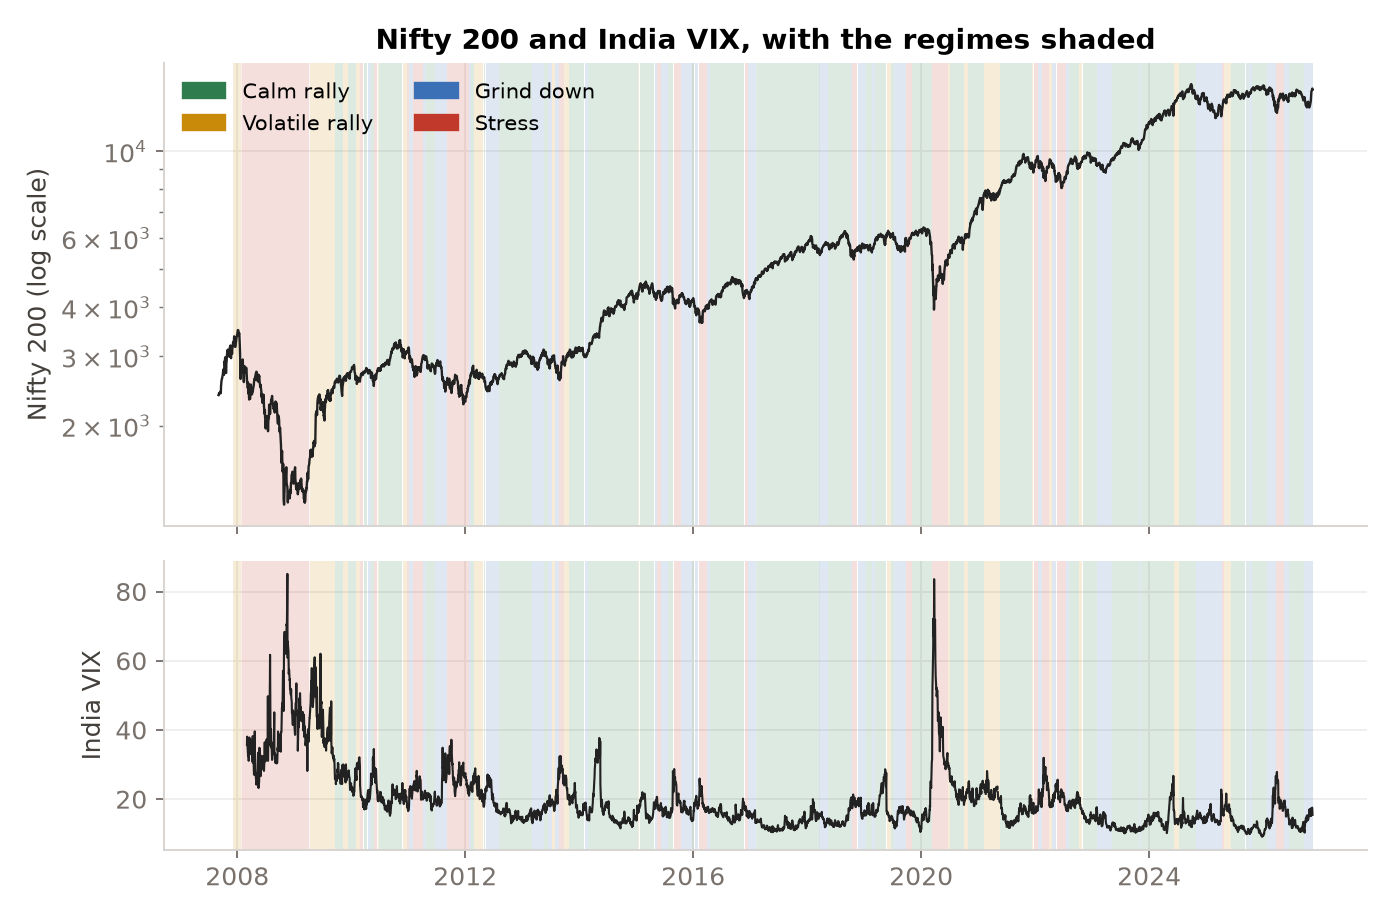

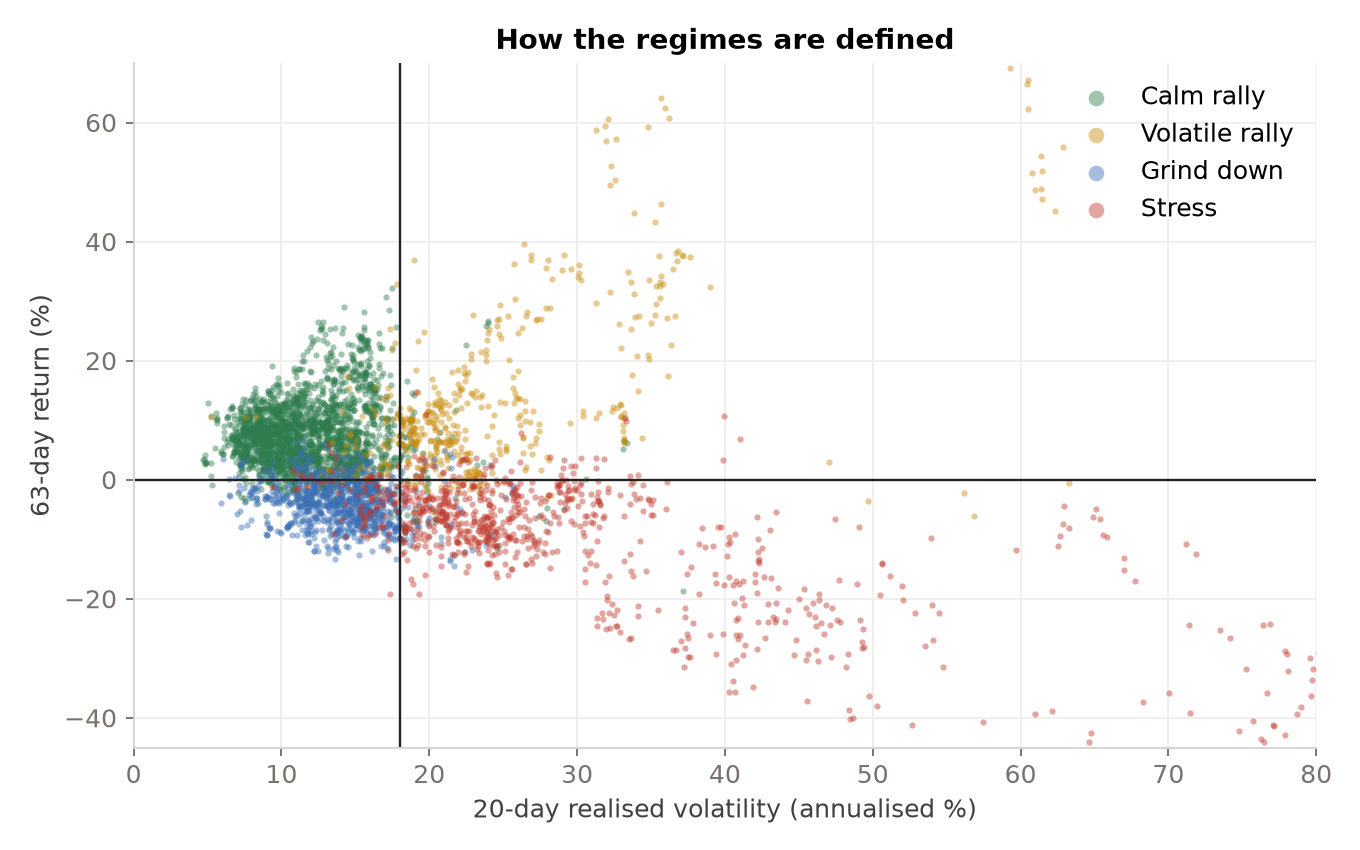

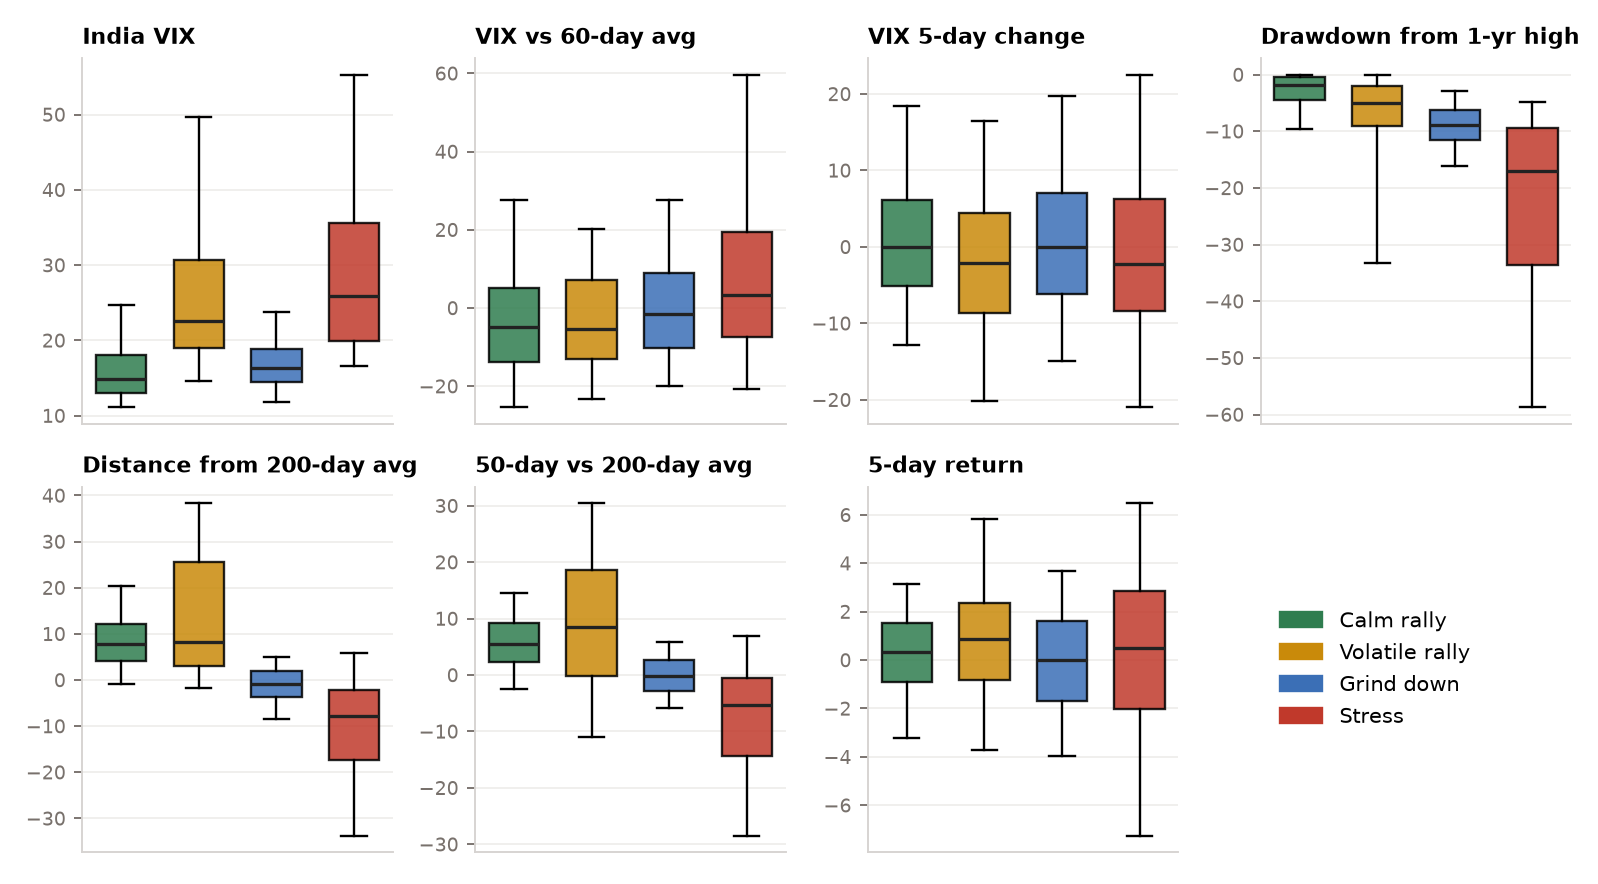

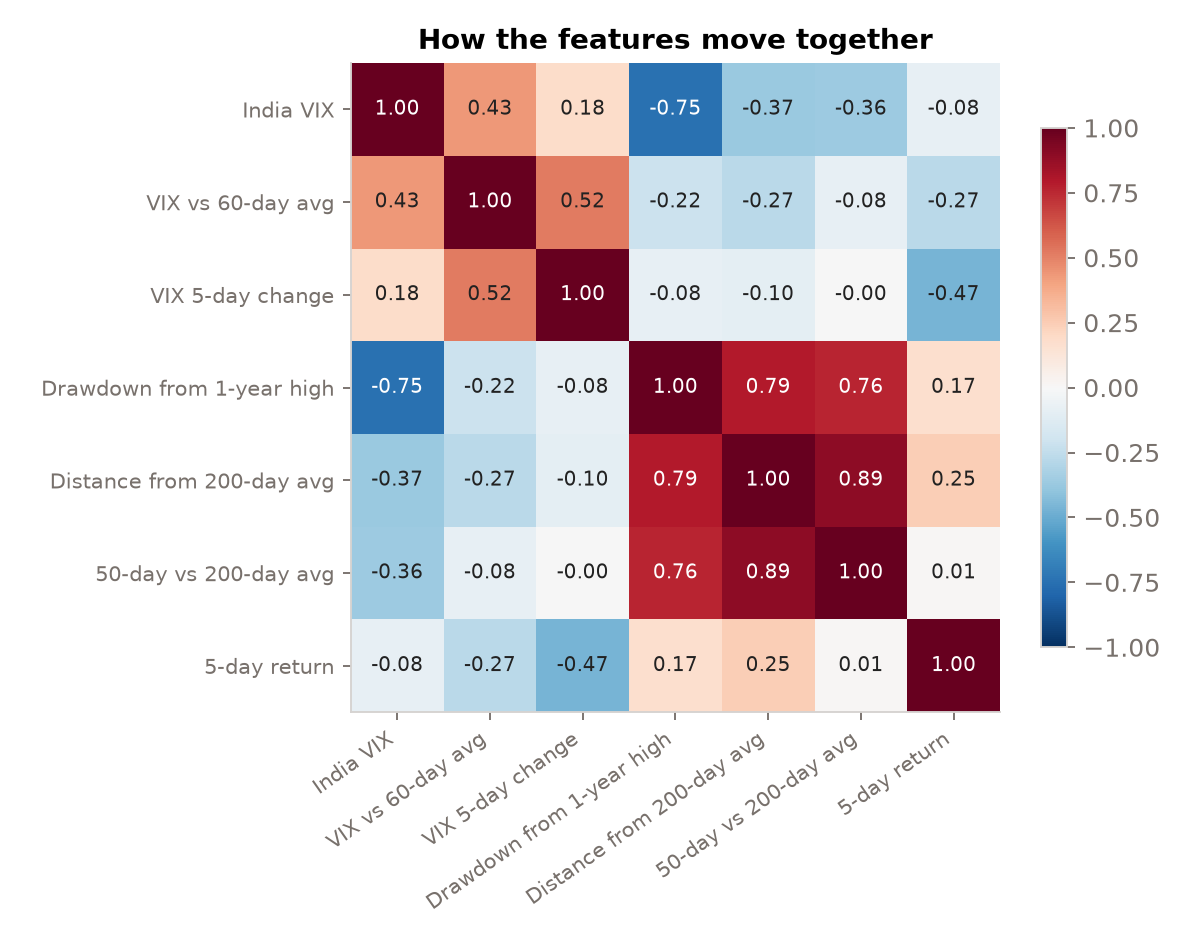

In [9]:
charts_dir = Path('../../src/MLPortfolio.Web/wwwroot/projects/nse-regime/charts')
for name in ['eda-history.png', 'eda-label-rule.png', 'eda-features-by-regime.png', 'eda-correlation.png']:
    display(Image(filename=str(charts_dir / name), width=700))

## 6. Train and test

Six expanding-window folds with a 63-day gap, four candidate models, and a most-common-regime baseline. Every score is from days the model had not seen. The exported model is the class-weighted logistic regression fitted on all days.

In [10]:
result = train.train_and_evaluate()
m = result.metrics
print(f"{m['n_oos']} out-of-sample days, {m['oos_period']}; chosen: {m['chosen']}")
print(f"ONNX vs sklearn max abs diff: {m['onnx_max_abs_diff']:.1e}")
comp = pd.DataFrame({k: {x: v.get(x) for x in ('accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc')} for k, v in m['comparison'].items()}).T
comp.round(3)

3864 out-of-sample days, 2011-02-10 to 2026-11-13; chosen: Logistic regression, balanced classes
ONNX vs sklearn max abs diff: 3.2e-07


,accuracy,balanced_accuracy,macro_f1,roc_auc
Logistic regression,0.682,0.487,0.480,0.843
"Logistic regression, balanced classes",0.695,0.562,0.556,0.861
Random forest,0.689,0.483,0.482,0.811
Gradient boosting,0.650,0.468,0.474,0.774
Always the most common regime,0.554,0.301,0.249,NaN


In [11]:
print(train.training_report(result))

| Fold | Trained on | Training days | Tested on | Test days | Most-common-regime guess | Model |
|---|---|---|---|---|---|---|
| 1 | Jun 2008 to Nov 2010 | 582 | Feb 2011 to Sep 2013 | 644 | 23.4% | 59.8% |
| 2 | Jun 2008 to Jun 2013 | 1,226 | Sep 2013 to May 2016 | 644 | 61.6% | 72.0% |
| 3 | Jun 2008 to Feb 2016 | 1,870 | May 2016 to Dec 2018 | 644 | 78.9% | 73.9% |
| 4 | Jun 2008 to Sep 2018 | 2,514 | Dec 2018 to Aug 2021 | 644 | 56.7% | 65.4% |
| 5 | Jun 2008 to May 2021 | 3,158 | Aug 2021 to Apr 2024 | 644 | 61.5% | 80.6% |
| 6 | Jun 2008 to Dec 2023 | 3,802 | Apr 2024 to Nov 2026 | 644 | 50.2% | 65.4% |

| Setting | Value |
|---|---|
| Algorithm | multinomial logistic regression (`LogisticRegression`, L2 penalty, C = 1) |
| Solver | lbfgs, converged in 33 iterations (limit 5,000) |
| Preprocessing | each feature standardised (mean 0, standard deviation 1), fitted on the training days only |
| Class weights | Calm rally 0.47, Volatile rally 2.49, Grind down 1.24, Stress 1.52 (bala

The tables above are the ones shown on the project page. The model charts (written by `train.py`):

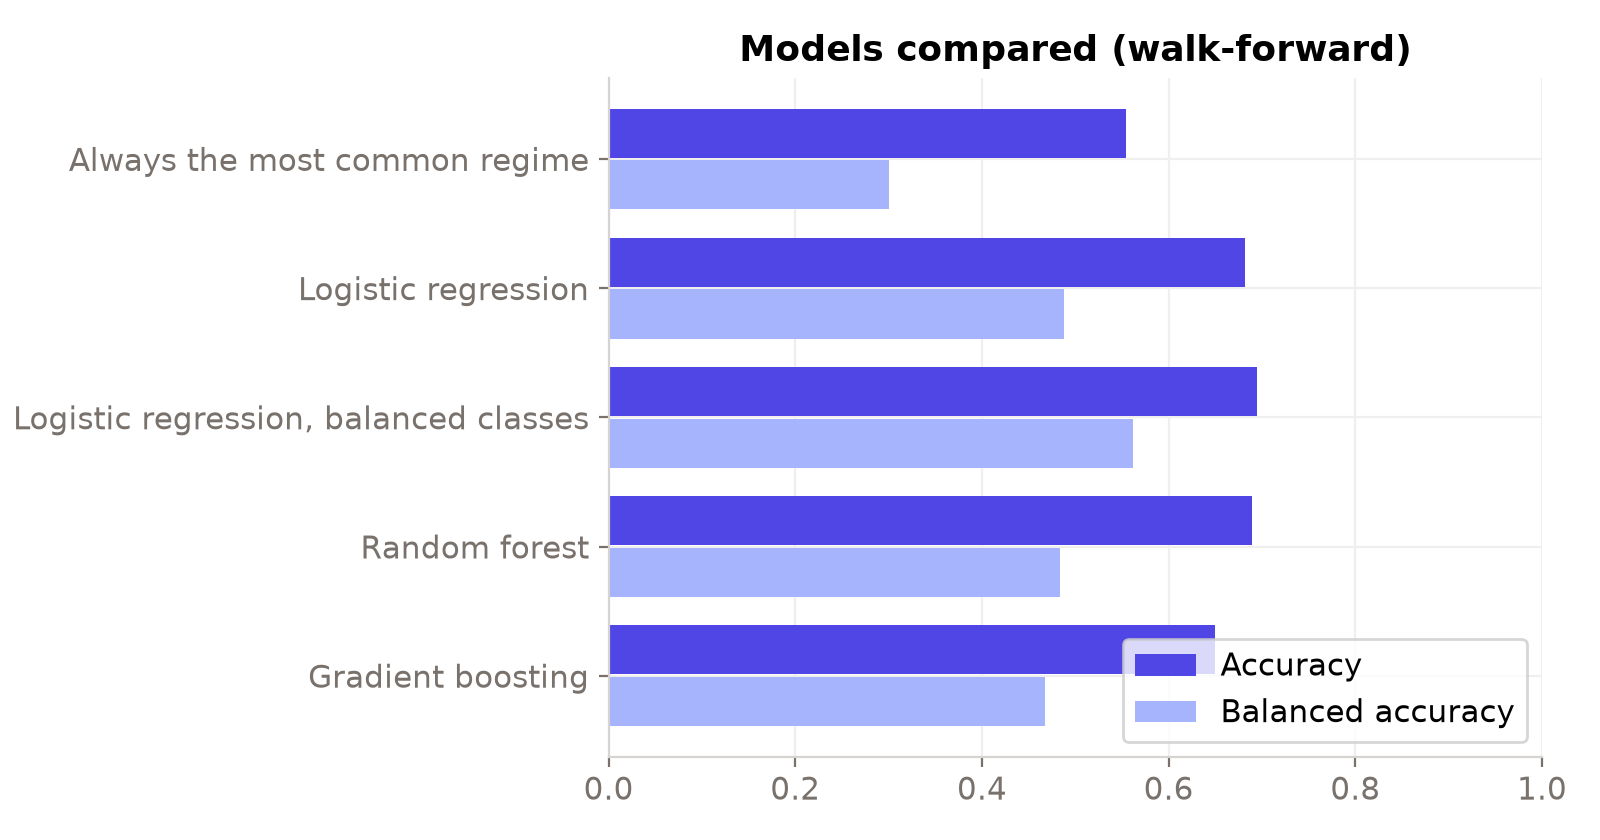

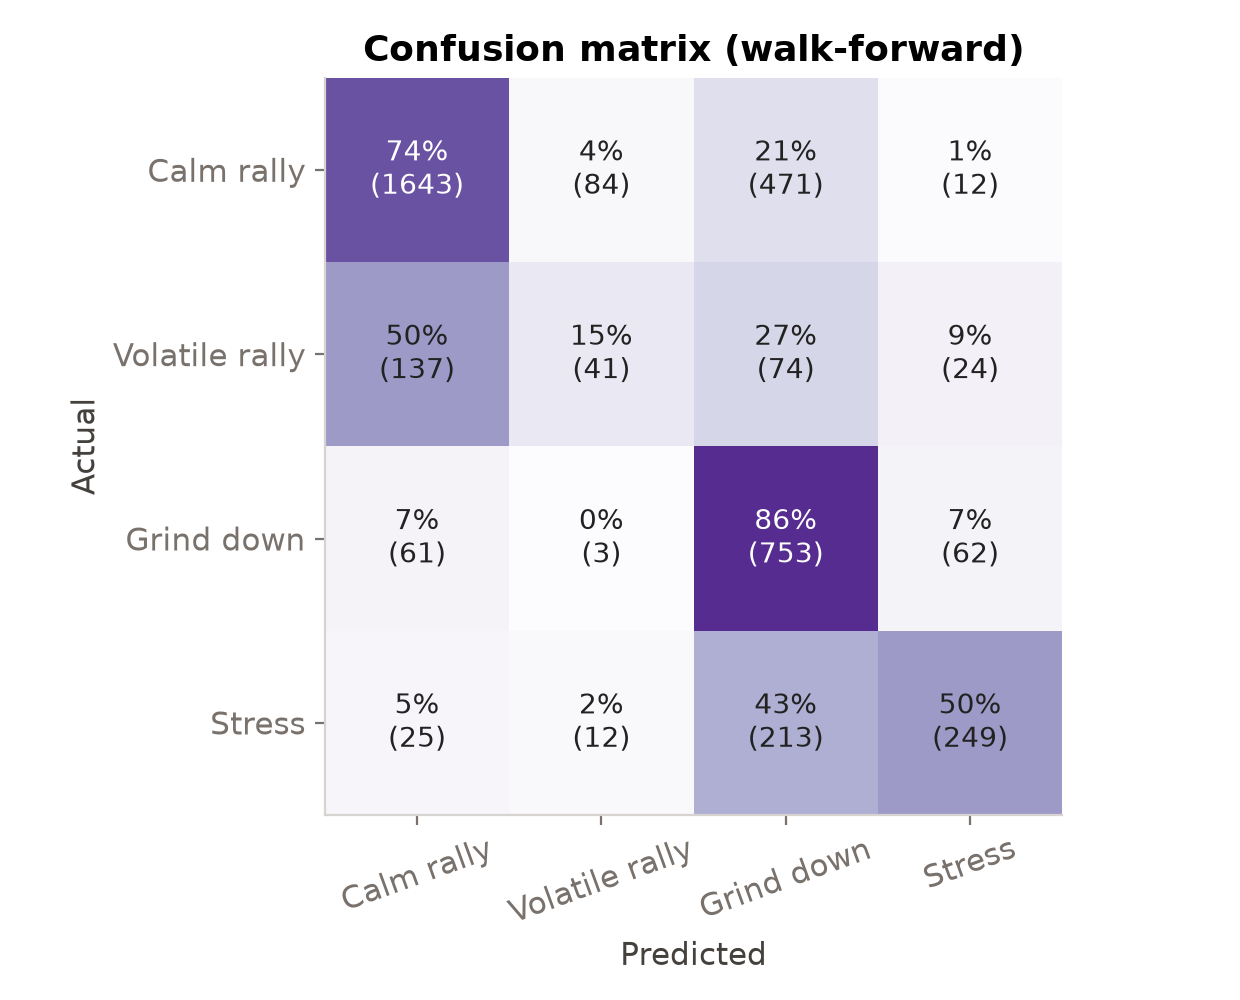

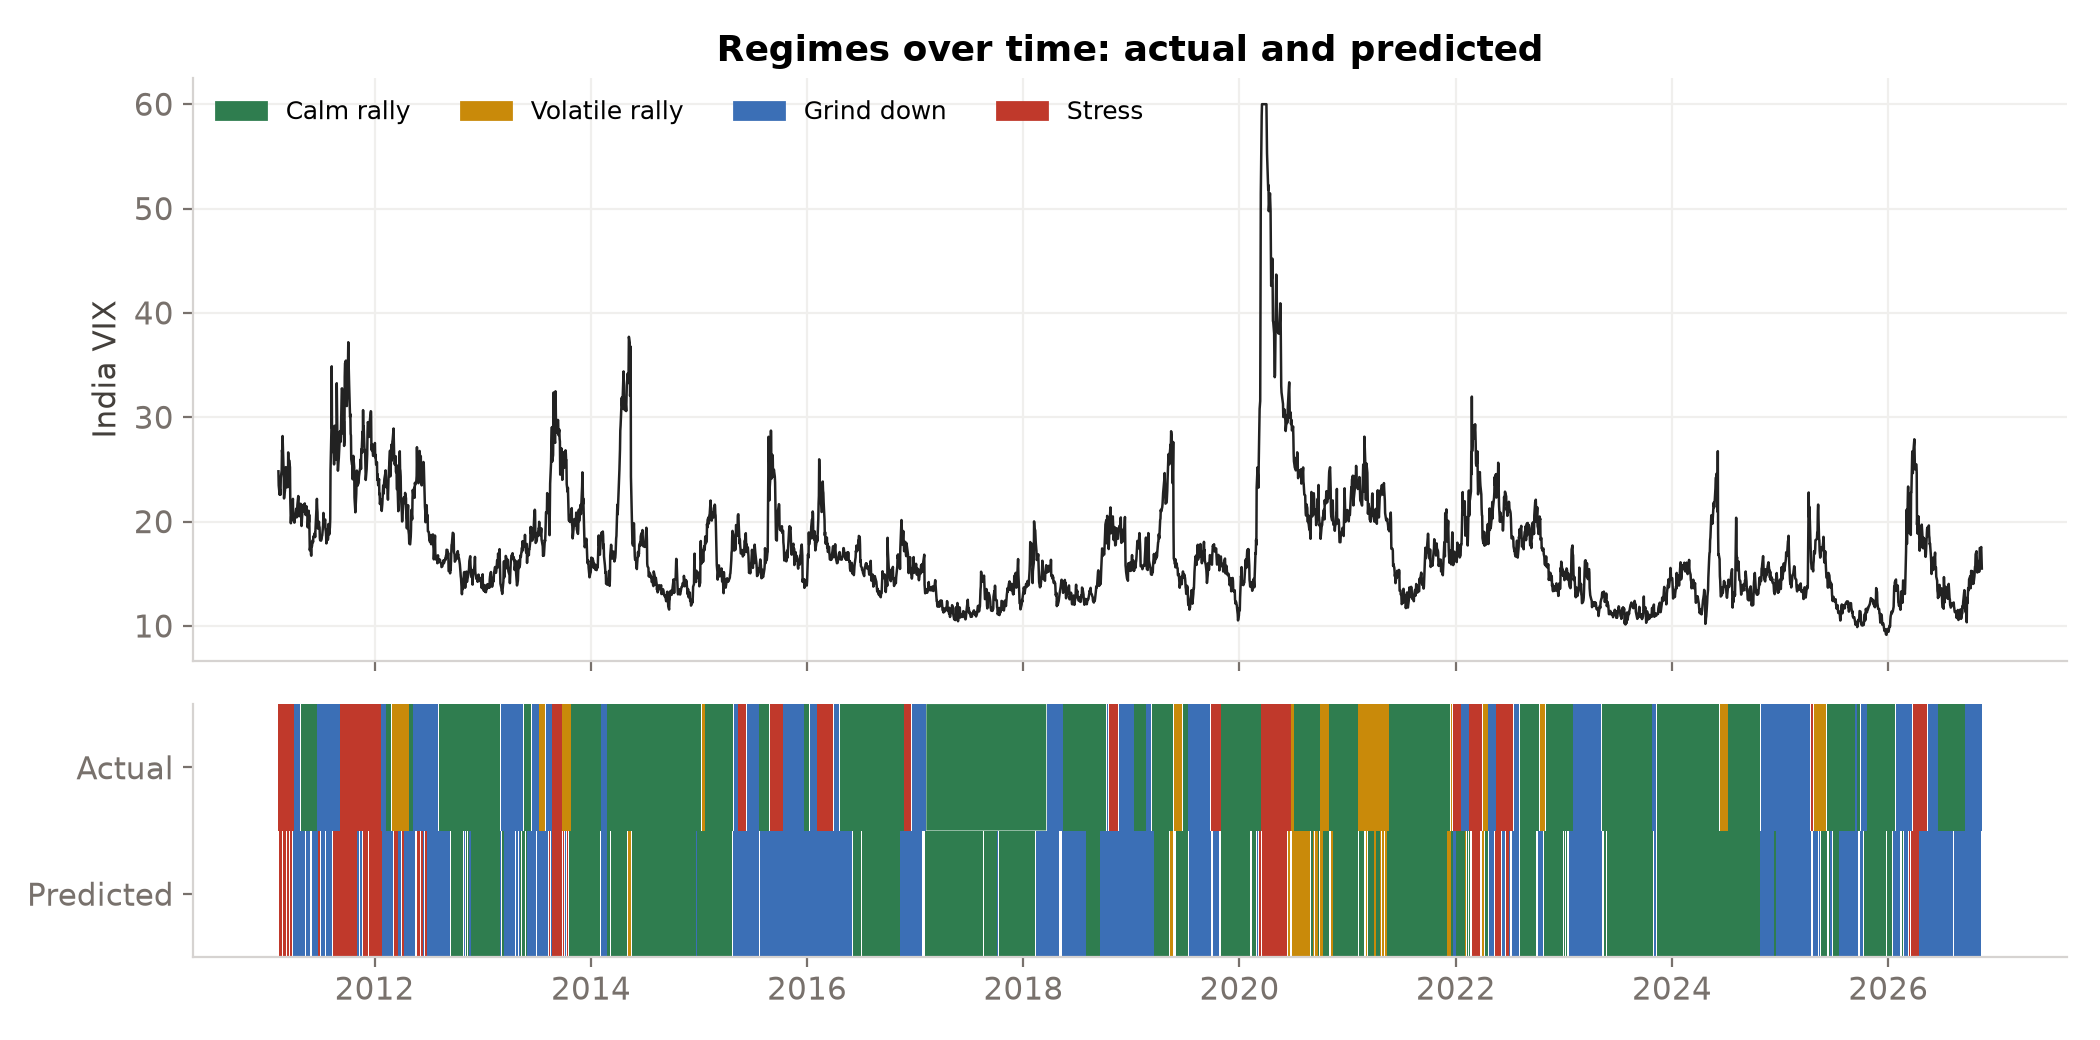

In [12]:
for name in ['model-comparison.png', 'confusion-matrix.png', 'regime-timeline.png']:
    display(Image(filename=str(charts_dir / name), width=700))

## 7. The current reading

The site shows the model's reading of the latest day's indicators, run through the exported ONNX model.

In [13]:
snapshot, reference = train.build_snapshot(result)
print(snapshot['asOf'])
print(pd.Series(snapshot['features']))
print()
print('The model predicts the current regime as:', reference['label'], '(illustrative)')
pd.Series(reference['probabilities']).round(3)

2026-11-13
india_vix            15.50
vix_vs_avg_pct       14.69
vix_change_5d_pct    -0.51
drawdown_pct         -2.40
dist_200dma_pct       4.28
ma50_vs_ma200_pct    -1.80
return_5d_pct         2.27
dtype: float64

The model predicts the current regime as: Calm rally (illustrative)


Calm rally        0.640
Volatile rally    0.111
Grind down        0.211
Stress            0.038
dtype: float64

## Site artefacts

`uv run python train.py` writes `model.onnx`, `schema.json`, `snapshot.json`, the charts and the .NET parity fixtures into the web app. `uv run python eda.py` writes the exploratory charts.